# Fourier Transforms

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch05/ch05-01.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** no setup is needed for this notebook. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

## Import packages

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [2]:
%matplotlib inline
# Define global "bold" style parameters
# This restores the thicker lines and fonts seen in older versions
plot_params = {
    # --- Fonts ---
    'font.size': 18,
    'font.family': 'sans-serif',
    
    # --- Axes (The Box) ---
    'axes.linewidth': 1.0,       # Thicker box around the plot
    
    # --- Lines (The Signal) ---
    'lines.linewidth': 2.5,      # Thicker default plot lines
}

# Apply these settings globally
plt.rcParams.update(plot_params)

## Define parameters

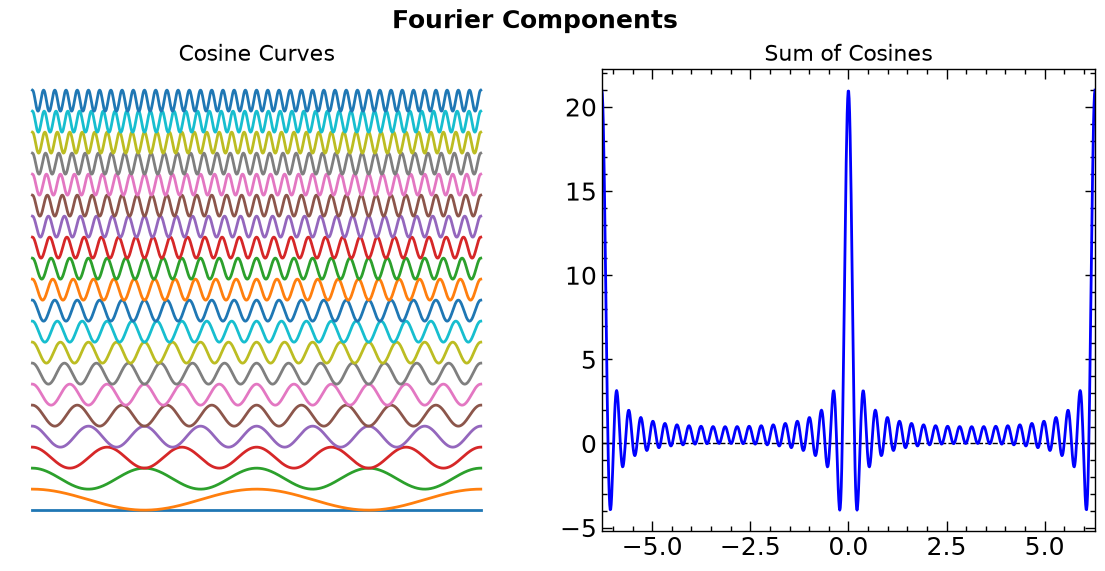

In [3]:
x1 = np.linspace(-2 * np.pi, 2 * np.pi, 1000)
k1 = np.arange(0, 21, 1)

x1matrix = x1[np.newaxis, :]
k1matrix = k1[:, np.newaxis]
y1 = np.cos(k1matrix * x1matrix) + 2 * k1matrix

y_sum = np.sum(np.cos(k1matrix * x1matrix), axis=0)

# Create the figure and subplots
fig1, (ax11, ax12) = plt.subplots(1, 2, figsize=(14, 6))
fig1.suptitle("Fourier Components", fontsize=18, fontweight='bold')

ax11.plot(x1, y1.T, linewidth=2)
   
ax11.set_title("Cosine Curves", fontsize=16)
ax11.axis('off')  # Turn off axes (Axes -> False)

ax12.plot(x1, y_sum, color='blue', linewidth=2)
ax12.set_title("Sum of Cosines", fontsize=16)
ax12.set_xlim([-2 * np.pi, 2 * np.pi])
ax12.minorticks_on()
ax12.tick_params(which='both',direction="in",width=1)
ax12.tick_params(which='major',length=7)
ax12.tick_params(which='minor',length=3.5)
ax12.xaxis.set_ticks_position('both')
ax12.yaxis.set_ticks_position('both')
ax12.axhline(0, color='black', linewidth=1, linestyle='--', zorder=0)
# Note: We keep the axes on for the sum plot as is standard, 
# though the Mathematica code implies a Frame around the graphic.

plt.show()

## Incorporate Slider

In [4]:
def plot_fourier_components(kmax):
    # Setup the domain x from -2pi to 2pi
    x = np.linspace(-2 * np.pi, 2 * np.pi, 1000)
    
    # Create the figure and subplots
    fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    fig1.suptitle("Fourier Components", fontsize=18, fontweight='bold')
    
    
    # --- Left Plot: Cosine Curves (Stacked) ---
    # Corresponds to: Table[Cos[k*x] + 2 k, {k, 0, kmax, 1}]
    for k in range(kmax + 1):
        # Calculate y for the current k, shifting it up by 2*k
        y = np.cos(k * x) + 2 * k
        ax1.plot(x, y, linewidth=2)
        
    ax1.set_title("Cosine Curves", fontsize=16)
    ax1.axis('off')  # Turn off axes (Axes -> False)
    
    # --- Right Plot: Sum of Cosines ---
    # Corresponds to: Total[Table[Cos[k*x], {k, 0, kmax, 1}]]
    # We sum cos(k*x) for k from 0 to kmax
    y_sum = np.zeros_like(x)
    for k in range(kmax + 1):
        y_sum += np.cos(k * x)
        
    ax2.plot(x, y_sum, color='k', linewidth=2)
    ax2.set_title("Sum of Cosines", fontsize=16)
    ax2.set_xlim([-2 * np.pi, 2 * np.pi])
    # Note: We keep the axes on for the sum plot as is standard, 
    # though the Mathematica code implies a Frame around the graphic.

    plt.show()

# Create the interactive slider
# Corresponds to: {{kmax, 1, "Max k value"}, 0, 20, 1}
interact(plot_fourier_components, 
         kmax=IntSlider(min=0, max=20, step=1, value=1, description='no. of cosines'));

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch05/ch05-01_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch05/ch05-01.html) (direct link: [ch05-01_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch05/ch05-01_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.